Entorno local detectado. Cargando desde: C:\Users\eduar\Downloads\VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261118.csv
DIMENSIONES DEL DATASET
(450335, 9)

PRIMEROS CINCO REGISTROS


,MARCA_VEHICULO,MODELO_VEHICULO,TIPO_VEHICULO,EDAD_VEHICULO,FECHA_ACCIDENTE,GRAVEDAD_ACCIDENTE,DEPARTAMENTO_ACCIDENTE,MUNICIPIO_ACCIDENTE,AUTORIDAD_DE_TRANSITO
0,VOLKSWAGEN,2018,CAMION,7,09/2026,CON HERIDOS,ANTIOQUIA,MEDELLIN,DIRECCION DE TRANSITO Y TRANSPORTE
1,AKT,2024,MOTOCICLETA,3,09/2026,CON HERIDOS,ANTIOQUIA,MEDELLIN,DIRECCION DE TRANSITO Y TRANSPORTE
2,YAMAHA,2022,MOTOCICLETA,5,09/2026,CON HERIDOS,ANTIOQUIA,GIRARDOTA,DIRECCION DE TRANSITO Y TRANSPORTE
3,FOTON,2022,TRACTOCAMION,5,09/2026,CON HERIDOS,ANTIOQUIA,GIRARDOTA,DIRECCION DE TRANSITO Y TRANSPORTE
4,YAMAHA,2023,MOTOCICLETA,4,09/2026,CON HERIDOS,SANTANDER,BUCARAMANGA,DIR TTOyTTE BUCARAMANGA



INFORMACIÓN DE LAS VARIABLES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450335 entries, 0 to 450334
Data columns (total 9 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   MARCA_VEHICULO          450335 non-null  object
 1   MODELO_VEHICULO         450335 non-null  int64 
 2   TIPO_VEHICULO           450335 non-null  object
 3   EDAD_VEHICULO           450315 non-null  object
 4   FECHA_ACCIDENTE         450335 non-null  object
 5   GRAVEDAD_ACCIDENTE      450335 non-null  object
 6   DEPARTAMENTO_ACCIDENTE  450335 non-null  object
 7   MUNICIPIO_ACCIDENTE     450335 non-null  object
 8   AUTORIDAD_DE_TRANSITO   450335 non-null  object
dtypes: int64(1), object(8)
memory usage: 30.9+ MB

VALORES FALTANTES
MARCA_VEHICULO             0
MODELO_VEHICULO            0
TIPO_VEHICULO              0
EDAD_VEHICULO             20
FECHA_ACCIDENTE            0
GRAVEDAD_ACCIDENTE         0
DEPARTAMENTO_ACCIDENTE     0
MUNI

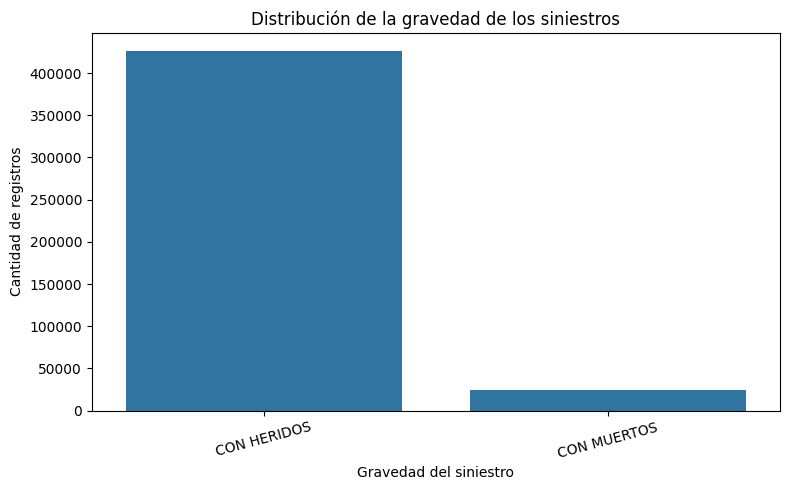

In [5]:

# ============================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ============================================

from io import BytesIO
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# ============================================
# 2. CARGA DEL ARCHIVO CSV (COLAB + LOCAL)
# ============================================

def cargar_csv(ruta_local=r"C:\Users\eduar\Downloads\VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261118.csv", encoding="utf-8"):
    """
    Carga el CSV desde Google Colab (mediante files.upload) si está disponible;
    en caso contrario, lo lee desde la ruta local indicada.
    """
    try:
        from google.colab import files
        print("Entorno Google Colab detectado. Selecciona tu archivo CSV...")
        uploaded = files.upload()
        nombre_archivo = next(iter(uploaded))
        return pd.read_csv(
            BytesIO(uploaded[nombre_archivo]),
            encoding=encoding,
            low_memory=False
        )
    except ModuleNotFoundError:
        if not os.path.exists(ruta_local):
            raise FileNotFoundError(
                f"No se encontró el archivo local en '{ruta_local}'. "
                "Actualiza 'ruta_local' con la ruta correcta de tu CSV."
            )
        print(f"Entorno local detectado. Cargando desde: {ruta_local}")
        return pd.read_csv(
            ruta_local,
            encoding=encoding,
            low_memory=False
        )


# Cambia "siniestros.csv" por la ruta local que uses habitualmente
RUTA_LOCAL = r"C:\Users\eduar\Downloads\VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261118.csv"
df = cargar_csv(ruta_local=RUTA_LOCAL, encoding="utf-8")


# ============================================
# 3. EXPLORACIÓN INICIAL
# ============================================

print("DIMENSIONES DEL DATASET")
print(df.shape)

print("\nPRIMEROS CINCO REGISTROS")
try:
    display(df.head())
except NameError:
    print(df.head())

print("\nINFORMACIÓN DE LAS VARIABLES")
df.info()


# ============================================
# 4. REVISIÓN DE VALORES FALTANTES
# ============================================

print("\nVALORES FALTANTES")
print(df.isnull().sum())


# ============================================
# 5. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
# ============================================

print("\nDISTRIBUCIÓN DE LA GRAVEDAD")
print(df["GRAVEDAD_ACCIDENTE"].value_counts(dropna=False))

print("\nPORCENTAJES")
print(
    df["GRAVEDAD_ACCIDENTE"]
    .value_counts(normalize=True, dropna=False) * 100
)


# ============================================
# 6. VISUALIZACIÓN DE LA GRAVEDAD
# ============================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="GRAVEDAD_ACCIDENTE",
    order=df["GRAVEDAD_ACCIDENTE"].value_counts().index
)

plt.title("Distribución de la gravedad de los siniestros")
plt.xlabel("Gravedad del siniestro")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ---------------------------------------------------------
# CARGA DEL DATASET
# ---------------------------------------------------------

# En Google Colab:
# Descomenta las siguientes líneas para cargar el archivo.
#
# from google.colab import files
# uploaded = files.upload()
# nombre_archivo = next(iter(uploaded))
# df = pd.read_csv(nombre_archivo, encoding="utf-8",
#                  low_memory=False)

# En VS Code:
ruta_archivo = Path(
    "VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261118.csv"
)

df = pd.read_csv(
    ruta_archivo,
    encoding="utf-8",
    low_memory=False
)

print("Dataset cargado correctamente")
print("Dimensiones originales:", df.shape)

# Crear una copia para conservar el archivo original
df_limpio = df.copy()


Dataset cargado correctamente
Dimensiones originales: (450335, 9)


In [7]:

# ---------------------------------------------------------
# NORMALIZACIÓN DE NOMBRES DE COLUMNAS
# ---------------------------------------------------------

df_limpio.columns = (
    df_limpio.columns
    .str.strip()
    .str.upper()
)

print("Nombres de las columnas:")
print(df_limpio.columns.tolist())


Nombres de las columnas:
['MARCA_VEHICULO', 'MODELO_VEHICULO', 'TIPO_VEHICULO', 'EDAD_VEHICULO', 'FECHA_ACCIDENTE', 'GRAVEDAD_ACCIDENTE', 'DEPARTAMENTO_ACCIDENTE', 'MUNICIPIO_ACCIDENTE', 'AUTORIDAD_DE_TRANSITO']


In [8]:

# ---------------------------------------------------------
# LIMPIEZA DE VARIABLES CATEGÓRICAS
# ---------------------------------------------------------

columnas_categoricas = [
    "MARCA_VEHICULO",
    "TIPO_VEHICULO",
    "GRAVEDAD_ACCIDENTE",
    "DEPARTAMENTO_ACCIDENTE",
    "MUNICIPIO_ACCIDENTE",
    "AUTORIDAD_DE_TRANSITO"
]

for columna in columnas_categoricas:

    df_limpio[columna] = (
        df_limpio[columna]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    # Convertir cadenas vacías en valores faltantes
    df_limpio[columna] = df_limpio[columna].replace(
        "", pd.NA
    )

print("Normalización categórica finalizada")

for columna in columnas_categoricas:
    print(
        columna,
        "-> categorías:",
        df_limpio[columna].nunique()
    )


Normalización categórica finalizada
MARCA_VEHICULO -> categorías: 381
TIPO_VEHICULO -> categorías: 31
GRAVEDAD_ACCIDENTE -> categorías: 2
DEPARTAMENTO_ACCIDENTE -> categorías: 31
MUNICIPIO_ACCIDENTE -> categorías: 663
AUTORIDAD_DE_TRANSITO -> categorías: 237


In [9]:

# ---------------------------------------------------------
# CONVERSIÓN DE EDAD DEL VEHÍCULO
# ---------------------------------------------------------

# Conservar temporalmente los valores originales
edad_original = df_limpio["EDAD_VEHICULO"].copy()

# Convertir a texto y retirar espacios
edad_texto = (
    edad_original
    .astype("string")
    .str.strip()
)

# Convertir a número.
# Los valores que no puedan interpretarse se convierten en NaN.
df_limpio["EDAD_VEHICULO"] = pd.to_numeric(
    edad_texto,
    errors="coerce"
)

# Identificar los valores que no pudieron convertirse
valores_invalidos = edad_texto[
    edad_texto.notna() &
    df_limpio["EDAD_VEHICULO"].isna()
].unique()

print("Valores originales no interpretables:")
print(valores_invalidos)

print("\nValores faltantes después de la conversión:")
print(df_limpio["EDAD_VEHICULO"].isna().sum())

print("\nEstadísticas de edad:")
print(df_limpio["EDAD_VEHICULO"].describe())


Valores originales no interpretables:
<StringArray>
['2,020', '1,826']
Length: 2, dtype: string

Valores faltantes después de la conversión:
22

Estadísticas de edad:
count     450313.0
mean     10.868252
std       7.538372
min            0.0
25%            5.0
50%            9.0
75%           15.0
max          127.0
Name: EDAD_VEHICULO, dtype: Float64


In [10]:

# ---------------------------------------------------------
# IDENTIFICACIÓN DE EDADES ATÍPICAS
# ---------------------------------------------------------

print("Edades superiores a 50 años:")

display(
    df_limpio.loc[
        df_limpio["EDAD_VEHICULO"] > 50,
        ["MODELO_VEHICULO", "EDAD_VEHICULO",
         "FECHA_ACCIDENTE", "TIPO_VEHICULO"]
    ].head(20)
)

print("\nFrecuencia de las edades más altas:")

display(
    df_limpio["EDAD_VEHICULO"]
    .value_counts()
    .sort_index()
    .tail(20)
)


Edades superiores a 50 años:


,MODELO_VEHICULO,EDAD_VEHICULO,FECHA_ACCIDENTE,TIPO_VEHICULO
371,1954,65,08/2026,CAMION
1020,1965,61,08/2026,CAMION
1197,1973,54,08/2026,BUS
1304,1973,53,08/2026,CAMION
1318,1960,64,08/2026,VOLQUETA
1320,1960,64,08/2026,VOLQUETA
1851,1968,59,08/2026,CAMION
1852,1968,59,08/2026,CAMION
2099,1970,56,08/2026,VOLQUETA
2594,1963,54,08/2026,CAMION



Frecuencia de las edades más altas:


EDAD_VEHICULO
67     47
68     31
69     13
70     40
71     45
72     40
73     33
74     17
75     16
76      8
77     13
78      2
79      4
80      2
81      5
85      1
87      1
107     2
118     2
127    59
Name: count, dtype: Int64

In [11]:

# ---------------------------------------------------------
# TRANSFORMACIÓN DE LA FECHA
# ---------------------------------------------------------

df_limpio["FECHA_ACCIDENTE"] = pd.to_datetime(
    df_limpio["FECHA_ACCIDENTE"],
    format="%m/%Y",
    errors="coerce"
)

# Extraer el año y el mes
df_limpio["ANIO_ACCIDENTE"] = (
    df_limpio["FECHA_ACCIDENTE"].dt.year
)

df_limpio["MES_ACCIDENTE"] = (
    df_limpio["FECHA_ACCIDENTE"].dt.month
)

print("Periodo de los registros:")

print(
    "Fecha inicial:",
    df_limpio["FECHA_ACCIDENTE"].min()
)

print(
    "Fecha final:",
    df_limpio["FECHA_ACCIDENTE"].max()
)

print("\nDistribución por año:")

display(
    df_limpio["ANIO_ACCIDENTE"]
    .value_counts()
    .sort_index()
)


Periodo de los registros:
Fecha inicial: 2022-01-01 00:00:00
Fecha final: 2026-09-01 00:00:00

Distribución por año:


ANIO_ACCIDENTE
2022    115201
2023    111898
2024    121050
2025     66891
2026     35295
Name: count, dtype: int64

,Valores_faltantes,Porcentaje
EDAD_VEHICULO,22,0.0049
MODELO_VEHICULO,0,0.0000
MARCA_VEHICULO,0,0.0000
TIPO_VEHICULO,0,0.0000
FECHA_ACCIDENTE,0,0.0000
GRAVEDAD_ACCIDENTE,0,0.0000
DEPARTAMENTO_ACCIDENTE,0,0.0000
MUNICIPIO_ACCIDENTE,0,0.0000
AUTORIDAD_DE_TRANSITO,0,0.0000
ANIO_ACCIDENTE,0,0.0000


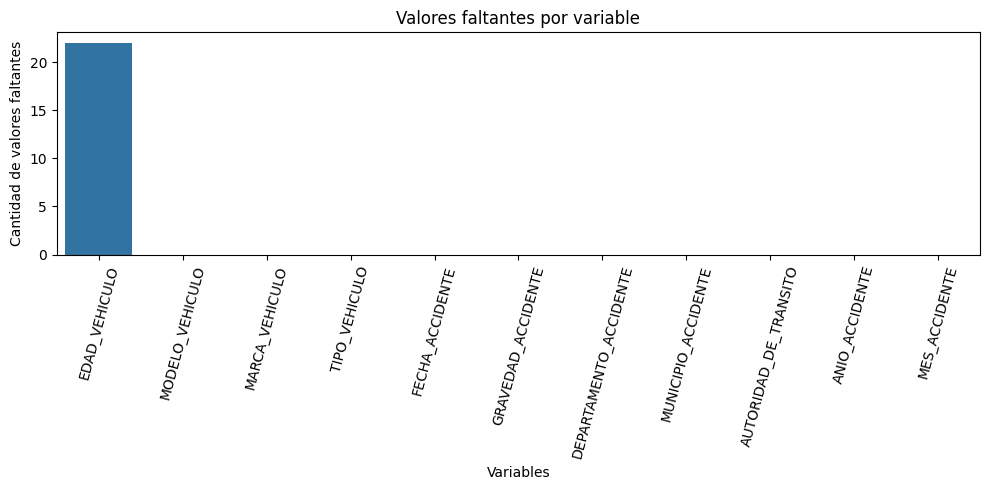

In [12]:

# ---------------------------------------------------------
# ANÁLISIS DE VALORES FALTANTES
# ---------------------------------------------------------

faltantes = pd.DataFrame({
    "Valores_faltantes": df_limpio.isnull().sum(),
    "Porcentaje": (
        df_limpio.isnull().mean() * 100
    ).round(4)
})

faltantes = faltantes.sort_values(
    by="Valores_faltantes",
    ascending=False
)

display(faltantes)

# Visualización de valores faltantes
plt.figure(figsize=(10, 5))

sns.barplot(
    x=faltantes.index,
    y=faltantes["Valores_faltantes"]
)

plt.title("Valores faltantes por variable")
plt.xlabel("Variables")
plt.ylabel("Cantidad de valores faltantes")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


In [13]:

# ---------------------------------------------------------
# IDENTIFICACIÓN DE REGISTROS DUPLICADOS
# ---------------------------------------------------------

duplicados = df_limpio.duplicated().sum()

porcentaje_duplicados = (
    duplicados / len(df_limpio)
) * 100

print("Registros duplicados:", duplicados)

print(
    "Porcentaje de duplicados:",
    round(porcentaje_duplicados, 2),
    "%"
)

# Mostrar algunos registros duplicados
display(
    df_limpio[
        df_limpio.duplicated(keep=False)
    ].head(10)
)

# IMPORTANTE:
# No eliminamos los duplicados automáticamente.
# El dataset no contiene un identificador único del siniestro.


Registros duplicados: 159399
Porcentaje de duplicados: 35.4 %


,MARCA_VEHICULO,MODELO_VEHICULO,TIPO_VEHICULO,EDAD_VEHICULO,FECHA_ACCIDENTE,GRAVEDAD_ACCIDENTE,DEPARTAMENTO_ACCIDENTE,MUNICIPIO_ACCIDENTE,AUTORIDAD_DE_TRANSITO,ANIO_ACCIDENTE,MES_ACCIDENTE
67,KYMCO,2014,MOTOCICLETA,13,2026-08-01,CON HERIDOS,ANTIOQUIA,SABANETA,STRIA TTOYTTE MCPAL SABANETA,2026,8
123,AKT,2026,MOTOCICLETA,1,2026-08-01,CON HERIDOS,SANTANDER,BUCARAMANGA,DIR TTOYTTE BUCARAMANGA,2026,8
124,AKT,2026,MOTOCICLETA,1,2026-08-01,CON HERIDOS,SANTANDER,BUCARAMANGA,DIR TTOYTTE BUCARAMANGA,2026,8
139,CHEVROLET,2008,AUTOMOVIL,19,2026-08-01,CON HERIDOS,SANTANDER,BUCARAMANGA,DIR TTOYTTE BUCARAMANGA,2026,8
152,SUZUKI,2014,MOTOCICLETA,13,2026-08-01,CON HERIDOS,SANTANDER,BUCARAMANGA,DIR TTOYTTE BUCARAMANGA,2026,8
155,YAMAHA,2023,MOTOCICLETA,4,2026-08-01,CON HERIDOS,SANTANDER,BUCARAMANGA,DIR TTOYTTE BUCARAMANGA,2026,8
156,YAMAHA,2015,MOTOCICLETA,11,2026-08-01,CON HERIDOS,SANTANDER,BUCARAMANGA,DIR TTOYTTE BUCARAMANGA,2026,8
158,HERO,2024,MOTOCICLETA,3,2026-08-01,CON HERIDOS,ANTIOQUIA,SABANETA,STRIA TTOYTTE MCPAL SABANETA,2026,8
170,YAMAHA,2025,MOTOCICLETA,2,2026-08-01,CON HERIDOS,ANTIOQUIA,SABANETA,STRIA TTOYTTE MCPAL SABANETA,2026,8
171,BAJAJ,2016,MOTOCICLETA,11,2026-08-01,CON HERIDOS,ANTIOQUIA,SABANETA,STRIA TTOYTTE MCPAL SABANETA,2026,8


In [14]:

# ---------------------------------------------------------
# VALIDACIÓN DE MODELO Y EDAD DEL VEHÍCULO
# ---------------------------------------------------------

df_limpio["EDAD_CALCULADA"] = (
    df_limpio["ANIO_ACCIDENTE"] -
    df_limpio["MODELO_VEHICULO"]
)

# Identificar posibles inconsistencias
inconsistencias = df_limpio[
    (df_limpio["EDAD_CALCULADA"] < 0) |
    (df_limpio["EDAD_CALCULADA"] > 100)
]

print(
    "Registros con posible inconsistencia:",
    len(inconsistencias)
)

display(
    inconsistencias[
        [
            "MODELO_VEHICULO",
            "ANIO_ACCIDENTE",
            "EDAD_VEHICULO",
            "EDAD_CALCULADA"
        ]
    ].head(20)
)

# Comparar edad reportada con edad calculada
display(
    df_limpio[
        [
            "MODELO_VEHICULO",
            "ANIO_ACCIDENTE",
            "EDAD_VEHICULO",
            "EDAD_CALCULADA"
        ]
    ].head(10)
)


Registros con posible inconsistencia: 15985


,MODELO_VEHICULO,ANIO_ACCIDENTE,EDAD_VEHICULO,EDAD_CALCULADA
94,2027,2026,0,-1
100,2027,2026,0,-1
102,2027,2026,0,-1
109,2027,2026,0,-1
110,2027,2026,0,-1
125,2027,2026,0,-1
127,2027,2026,1,-1
131,2027,2026,0,-1
132,2027,2026,0,-1
211,2027,2026,0,-1


,MODELO_VEHICULO,ANIO_ACCIDENTE,EDAD_VEHICULO,EDAD_CALCULADA
0,2018,2026,7,8
1,2024,2026,3,2
2,2022,2026,5,4
3,2022,2026,5,4
4,2023,2026,4,3
5,2017,2026,10,9
6,2019,2026,8,7
7,1981,2026,46,45
8,2022,2026,5,4
9,2022,2026,4,4


In [15]:

# ---------------------------------------------------------
# VALIDACIÓN DE LA VARIABLE OBJETIVO
# ---------------------------------------------------------

print("Valores de la variable objetivo:")

display(
    df_limpio["GRAVEDAD_ACCIDENTE"].value_counts(
        dropna=False
    )
)

# Comprobar las categorías existentes
print("\nCategorías identificadas:")

print(
    df_limpio["GRAVEDAD_ACCIDENTE"].unique()
)

# Revisar valores faltantes
print(
    "\nValores faltantes en la variable objetivo:",
    df_limpio["GRAVEDAD_ACCIDENTE"].isna().sum()
)

# Eliminar únicamente registros sin variable objetivo,
# si llegaran a existir.
df_limpio = df_limpio.dropna(
    subset=["GRAVEDAD_ACCIDENTE"]
).copy()

print("\nDimensiones después de validar el objetivo:")
print(df_limpio.shape)


Valores de la variable objetivo:


GRAVEDAD_ACCIDENTE
CON HERIDOS    426436
CON MUERTOS     23899
Name: count, dtype: Int64


Categorías identificadas:
<StringArray>
['CON HERIDOS', 'CON MUERTOS']
Length: 2, dtype: string

Valores faltantes en la variable objetivo: 0

Dimensiones después de validar el objetivo:
(450335, 12)


In [16]:

# ---------------------------------------------------------
# DEFINICIÓN DE VARIABLES PREDICTORAS Y OBJETIVO
# ---------------------------------------------------------

columnas_predictoras = [
    "MARCA_VEHICULO",
    "MODELO_VEHICULO",
    "TIPO_VEHICULO",
    "EDAD_VEHICULO",
    "ANIO_ACCIDENTE",
    "MES_ACCIDENTE",
    "DEPARTAMENTO_ACCIDENTE",
    "MUNICIPIO_ACCIDENTE"
]

# Matriz de características
X = df_limpio[columnas_predictoras].copy()

# Variable objetivo
y = df_limpio["GRAVEDAD_ACCIDENTE"].copy()

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nVariables predictoras:")
print(X.columns.tolist())

print("\nDistribución de la variable objetivo:")
display(y.value_counts(normalize=True) * 100)


Dimensiones de X: (450335, 8)
Dimensiones de y: (450335,)

Variables predictoras:
['MARCA_VEHICULO', 'MODELO_VEHICULO', 'TIPO_VEHICULO', 'EDAD_VEHICULO', 'ANIO_ACCIDENTE', 'MES_ACCIDENTE', 'DEPARTAMENTO_ACCIDENTE', 'MUNICIPIO_ACCIDENTE']

Distribución de la variable objetivo:


GRAVEDAD_ACCIDENTE
CON HERIDOS    94.693062
CON MUERTOS     5.306938
Name: proportion, dtype: Float64

In [17]:

# ---------------------------------------------------------
# RESUMEN FINAL DE LA PREPARACIÓN
# ---------------------------------------------------------

print("=" * 55)
print("RESUMEN DE LIMPIEZA Y PREPARACIÓN")
print("=" * 55)

print("Registros:", len(df_limpio))
print("Variables:", df_limpio.shape[1])

print(
    "Valores faltantes:",
    df_limpio.isnull().sum().sum()
)

print(
    "Duplicados:",
    df_limpio.duplicated().sum()
)

print(
    "Variables predictoras:",
    X.shape[1]
)

print("\nDistribución de clases:")

display(
    y.value_counts().to_frame(
        name="Cantidad de registros"
    )
)

print("\nTipos de datos:")

display(
    df_limpio.dtypes.to_frame(
        name="Tipo de dato"
    )
)


RESUMEN DE LIMPIEZA Y PREPARACIÓN
Registros: 450335
Variables: 12
Valores faltantes: 22
Duplicados: 159399
Variables predictoras: 8

Distribución de clases:


,Cantidad de registros
GRAVEDAD_ACCIDENTE,
CON HERIDOS,426436
CON MUERTOS,23899



Tipos de datos:


,Tipo de dato
MARCA_VEHICULO,string[python]
MODELO_VEHICULO,int64
TIPO_VEHICULO,string[python]
EDAD_VEHICULO,Int64
FECHA_ACCIDENTE,datetime64[ns]
GRAVEDAD_ACCIDENTE,string[python]
DEPARTAMENTO_ACCIDENTE,string[python]
MUNICIPIO_ACCIDENTE,string[python]
AUTORIDAD_DE_TRANSITO,string[python]
ANIO_ACCIDENTE,int32


In [18]:

# ---------------------------------------------------------
# EXPORTAR DATASET PREPARADO
# ---------------------------------------------------------

nombre_salida = "vehiculos_siniestros_limpio.csv"

df_limpio.to_csv(
    nombre_salida,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo guardado:", nombre_salida)

# En Google Colab, descomentar para descargar:
#
# from google.colab import files
# files.download(nombre_salida)


Archivo guardado: vehiculos_siniestros_limpio.csv


In [19]:

# ---------------------------------------------------------
# AJUSTES FINALES DE CALIDAD DE DATOS
# ---------------------------------------------------------

# 1. Tratar edades superiores a 100 años como faltantes.
# Se consideran valores sospechosos y no edades válidas
# para el análisis inicial.

mascara_edad_invalida = (
    df_limpio["EDAD_VEHICULO"] > 100
)

cantidad_edad_invalida = mascara_edad_invalida.sum()

df_limpio.loc[
    mascara_edad_invalida,
    "EDAD_VEHICULO"
] = np.nan

print(
    "Edades superiores a 100 tratadas como faltantes:",
    cantidad_edad_invalida
)

# 2. Reconstruir las variables predictoras
columnas_predictoras = [
    "MARCA_VEHICULO",
    "MODELO_VEHICULO",
    "TIPO_VEHICULO",
    "EDAD_VEHICULO",
    "ANIO_ACCIDENTE",
    "MES_ACCIDENTE",
    "DEPARTAMENTO_ACCIDENTE",
    "MUNICIPIO_ACCIDENTE"
]

X = df_limpio[columnas_predictoras].copy()

y = df_limpio["GRAVEDAD_ACCIDENTE"].copy()

# 3. Verificar dimensiones y faltantes

print("\nDimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nValores faltantes en las variables predictoras:")

display(X.isnull().sum())

print("\nDistribución de la variable objetivo:")

display(y.value_counts())


Edades superiores a 100 tratadas como faltantes: 63

Dimensiones de X: (450335, 8)
Dimensiones de y: (450335,)

Valores faltantes en las variables predictoras:


MARCA_VEHICULO             0
MODELO_VEHICULO            0
TIPO_VEHICULO              0
EDAD_VEHICULO             85
ANIO_ACCIDENTE             0
MES_ACCIDENTE              0
DEPARTAMENTO_ACCIDENTE     0
MUNICIPIO_ACCIDENTE        0
dtype: int64


Distribución de la variable objetivo:


GRAVEDAD_ACCIDENTE
CON HERIDOS    426436
CON MUERTOS     23899
Name: count, dtype: Int64

In [20]:

# ---------------------------------------------------------
# SEPARACIÓN TEMPORAL DEL DATASET
# ---------------------------------------------------------

# Entrenamiento: años 2022, 2023 y 2024
mascara_train = (
    df_limpio["ANIO_ACCIDENTE"] <= 2024
)

# Prueba: años 2025 y 2026
mascara_test = (
    df_limpio["ANIO_ACCIDENTE"] >= 2025
)

X_train = X.loc[mascara_train].copy()
X_test = X.loc[mascara_test].copy()

y_train = y.loc[mascara_train].copy()
y_test = y.loc[mascara_test].copy()

print("REGISTROS DE ENTRENAMIENTO")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nREGISTROS DE PRUEBA")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nDistribución de clases en entrenamiento:")
display(y_train.value_counts(normalize=True) * 100)

print("\nDistribución de clases en prueba:")
display(y_test.value_counts(normalize=True) * 100)


REGISTROS DE ENTRENAMIENTO
X_train: (348149, 8)
y_train: (348149,)

REGISTROS DE PRUEBA
X_test: (102186, 8)
y_test: (102186,)

Distribución de clases en entrenamiento:


GRAVEDAD_ACCIDENTE
CON HERIDOS    95.442469
CON MUERTOS     4.557531
Name: proportion, dtype: Float64


Distribución de clases en prueba:


GRAVEDAD_ACCIDENTE
CON HERIDOS    92.139823
CON MUERTOS     7.860177
Name: proportion, dtype: Float64

In [21]:

# ---------------------------------------------------------
# LIBRERÍAS PARA CONSTRUIR Y EVALUAR EL MODELO
# ---------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("Librerías importadas correctamente")


Librerías importadas correctamente


In [22]:

# ---------------------------------------------------------
# IDENTIFICACIÓN DE LOS TIPOS DE VARIABLES
# ---------------------------------------------------------

variables_numericas = [
    "MODELO_VEHICULO",
    "EDAD_VEHICULO",
    "ANIO_ACCIDENTE",
    "MES_ACCIDENTE"
]

variables_categoricas = [
    "MARCA_VEHICULO",
    "TIPO_VEHICULO",
    "DEPARTAMENTO_ACCIDENTE",
    "MUNICIPIO_ACCIDENTE"
]

print("Variables numéricas:")
print(variables_numericas)

print("\nVariables categóricas:")
print(variables_categoricas)


Variables numéricas:
['MODELO_VEHICULO', 'EDAD_VEHICULO', 'ANIO_ACCIDENTE', 'MES_ACCIDENTE']

Variables categóricas:
['MARCA_VEHICULO', 'TIPO_VEHICULO', 'DEPARTAMENTO_ACCIDENTE', 'MUNICIPIO_ACCIDENTE']


In [23]:

# ---------------------------------------------------------
# TRANSFORMACIÓN DE VARIABLES NUMÉRICAS
# ---------------------------------------------------------

transformador_numerico = Pipeline(
    steps=[
        (
            "imputador",
            SimpleImputer(strategy="median")
        )
    ]
)

# ---------------------------------------------------------
# TRANSFORMACIÓN DE VARIABLES CATEGÓRICAS
# ---------------------------------------------------------

transformador_categorico = Pipeline(
    steps=[
        (
            "imputador",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "codificador",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=50,
                sparse_output=True
            )
        )
    ]
)

# ---------------------------------------------------------
# COMBINAR TRANSFORMACIONES
# ---------------------------------------------------------

preprocesador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            transformador_numerico,
            variables_numericas
        ),
        (
            "categoricas",
            transformador_categorico,
            variables_categoricas
        )
    ]
)

print("Preprocesador construido correctamente")



Preprocesador construido correctamente


In [24]:

# ---------------------------------------------------------
# CONFIGURACIÓN DEL CLASIFICADOR RANDOM FOREST
# ---------------------------------------------------------

modelo_rf = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("Clasificador Random Forest configurado")


Clasificador Random Forest configurado


In [25]:

# ---------------------------------------------------------
# PIPELINE COMPLETO
# ---------------------------------------------------------

pipeline_rf = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("clasificador", modelo_rf)
    ]
)

print("Pipeline de Machine Learning construido")

display(pipeline_rf)


Pipeline de Machine Learning construido


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold:

In [26]:

# ---------------------------------------------------------
# ENTRENAMIENTO DEL MODELO
# ---------------------------------------------------------

print("Iniciando entrenamiento de Random Forest...")

pipeline_rf.fit(X_train, y_train)

print("\nEntrenamiento finalizado correctamente")


Iniciando entrenamiento de Random Forest...

Entrenamiento finalizado correctamente


In [27]:

# ---------------------------------------------------------
# PREDICCIONES SOBRE EL CONJUNTO DE PRUEBA
# ---------------------------------------------------------

# Predicciones de las categorías
y_pred = pipeline_rf.predict(X_test)

# Probabilidades de pertenecer a cada categoría
y_prob = pipeline_rf.predict_proba(X_test)

# Identificar la columna correspondiente a CON MUERTOS
clases_modelo = pipeline_rf.named_steps[
    "clasificador"
].classes_

indice_muertos = list(clases_modelo).index(
    "CON MUERTOS"
)

probabilidad_muertos = y_prob[:, indice_muertos]

print("Predicciones generadas correctamente")
print("\nPrimeras 10 predicciones:")
print(y_pred[:10])

print("\nPrimeras 10 probabilidades de CON MUERTOS:")
print(probabilidad_muertos[:10])


Predicciones generadas correctamente

Primeras 10 predicciones:
['CON HERIDOS' 'CON HERIDOS' 'CON HERIDOS' 'CON HERIDOS' 'CON HERIDOS'
 'CON HERIDOS' 'CON HERIDOS' 'CON MUERTOS' 'CON MUERTOS' 'CON MUERTOS']

Primeras 10 probabilidades de CON MUERTOS:
[0.23536031 0.04101396 0.13085251 0.40053186 0.30646597 0.29310856
 0.34408132 0.51669785 0.79573823 0.71506886]


In [28]:

# ---------------------------------------------------------
# EVALUACIÓN DEL MODELO
# ---------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

balanced_accuracy = balanced_accuracy_score(
    y_test, y_pred
)

precision_muertos = precision_score(
    y_test,
    y_pred,
    pos_label="CON MUERTOS",
    zero_division=0
)

recall_muertos = recall_score(
    y_test,
    y_pred,
    pos_label="CON MUERTOS",
    zero_division=0
)

f1_muertos = f1_score(
    y_test,
    y_pred,
    pos_label="CON MUERTOS",
    zero_division=0
)

roc_auc = roc_auc_score(
    (y_test == "CON MUERTOS").astype(int),
    probabilidad_muertos
)

average_precision = average_precision_score(
    (y_test == "CON MUERTOS").astype(int),
    probabilidad_muertos
)

# Organizar las métricas
resultados = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision - CON MUERTOS",
        "Recall - CON MUERTOS",
        "F1-score - CON MUERTOS",
        "ROC-AUC",
        "Average Precision"
    ],
    "Resultado": [
        accuracy,
        balanced_accuracy,
        precision_muertos,
        recall_muertos,
        f1_muertos,
        roc_auc,
        average_precision
    ]
})

resultados["Resultado"] = resultados["Resultado"].round(4)

display(resultados)


,Métrica,Resultado
0,Accuracy,0.7867
1,Balanced Accuracy,0.6856
2,Precision - CON MUERTOS,0.1988
3,Recall - CON MUERTOS,0.5656
4,F1-score - CON MUERTOS,0.2942
5,ROC-AUC,0.7693
6,Average Precision,0.2369


In [29]:

# ---------------------------------------------------------
# INFORME DETALLADO DE CLASIFICACIÓN
# ---------------------------------------------------------

print(
    classification_report(
        y_test,
        y_pred,
        labels=["CON HERIDOS", "CON MUERTOS"],
        zero_division=0,
        digits=4
    )
)


              precision    recall  f1-score   support

 CON HERIDOS     0.9560    0.8055    0.8743     94154
 CON MUERTOS     0.1988    0.5656    0.2942      8032

    accuracy                         0.7867    102186
   macro avg     0.5774    0.6856    0.5843    102186
weighted avg     0.8965    0.7867    0.8287    102186



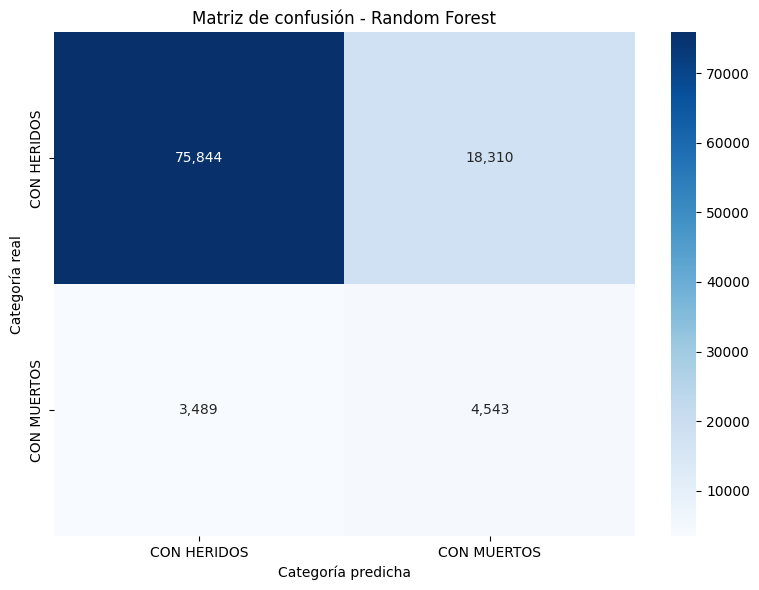

In [30]:

# ---------------------------------------------------------
# MATRIZ DE CONFUSIÓN
# ---------------------------------------------------------

etiquetas = ["CON HERIDOS", "CON MUERTOS"]

matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=etiquetas
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=etiquetas,
    yticklabels=etiquetas
)

plt.title("Matriz de confusión - Random Forest")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")

plt.tight_layout()
plt.show()


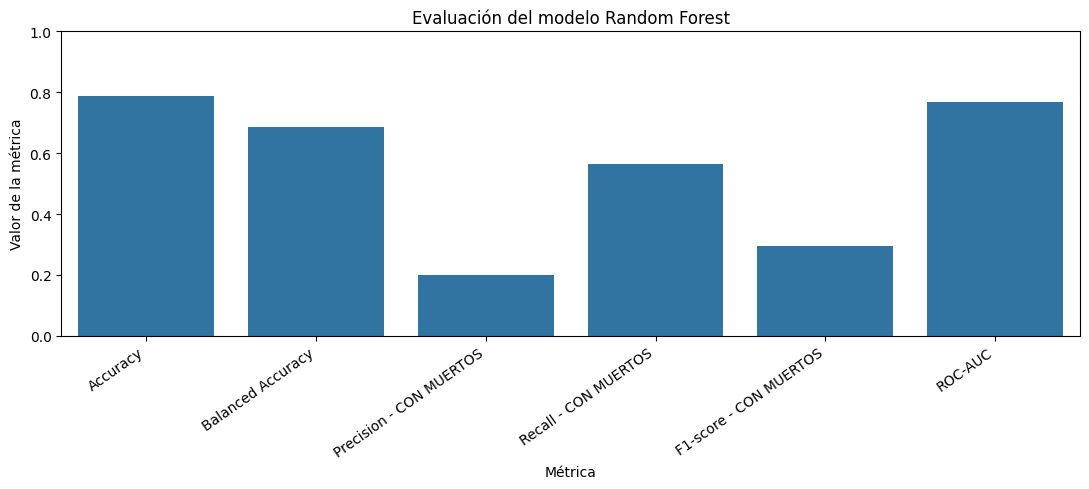

In [31]:

# ---------------------------------------------------------
# GRÁFICO DE MÉTRICAS
# ---------------------------------------------------------

metricas_grafico = resultados[
    resultados["Métrica"].isin([
        "Accuracy",
        "Balanced Accuracy",
        "Precision - CON MUERTOS",
        "Recall - CON MUERTOS",
        "F1-score - CON MUERTOS",
        "ROC-AUC"
    ])
]

plt.figure(figsize=(11, 5))

sns.barplot(
    data=metricas_grafico,
    x="Métrica",
    y="Resultado"
)

plt.title("Evaluación del modelo Random Forest")
plt.ylabel("Valor de la métrica")
plt.xlabel("Métrica")

plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


In [32]:

# ---------------------------------------------------------
# SEPARACIÓN TEMPORAL PARA OPTIMIZAR EL UMBRAL
# ---------------------------------------------------------

# Entrenamiento de optimización: 2022 y 2023
mask_train_opt = (
    df_limpio["ANIO_ACCIDENTE"] <= 2023
)

# Validación: año 2024
mask_validacion = (
    df_limpio["ANIO_ACCIDENTE"] == 2024
)

X_train_opt = X.loc[mask_train_opt].copy()
y_train_opt = y.loc[mask_train_opt].copy()

X_validacion = X.loc[mask_validacion].copy()
y_validacion = y.loc[mask_validacion].copy()

print("ENTRENAMIENTO")
print(X_train_opt.shape)
print(y_train_opt.value_counts(normalize=True) * 100)

print("\nVALIDACIÓN")
print(X_validacion.shape)
print(y_validacion.value_counts(normalize=True) * 100)


ENTRENAMIENTO
(227099, 8)
GRAVEDAD_ACCIDENTE
CON HERIDOS    95.343
CON MUERTOS     4.657
Name: proportion, dtype: Float64

VALIDACIÓN
(121050, 8)
GRAVEDAD_ACCIDENTE
CON HERIDOS    95.629079
CON MUERTOS     4.370921
Name: proportion, dtype: Float64


In [33]:

# ---------------------------------------------------------
# ENTRENAMIENTO CON DATOS DE 2022 Y 2023
# ---------------------------------------------------------

modelo_optimizacion = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "clasificador",
            RandomForestClassifier(
                n_estimators=300,
                max_features="sqrt",
                min_samples_leaf=2,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Entrenando modelo de optimización...")

modelo_optimizacion.fit(
    X_train_opt,
    y_train_opt
)

print("Entrenamiento finalizado")


Entrenando modelo de optimización...
Entrenamiento finalizado


In [34]:

# ---------------------------------------------------------
# COMPARACIÓN DE UMBRALES
# ---------------------------------------------------------

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# Obtener probabilidades de validación
prob_validacion = modelo_optimizacion.predict_proba(
    X_validacion
)

clases = list(
    modelo_optimizacion.named_steps[
        "clasificador"
    ].classes_
)

indice_muertos = clases.index("CON MUERTOS")

prob_muertos_validacion = (
    prob_validacion[:, indice_muertos]
)

umbrales = [
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60
]

resultados_umbrales = []

for umbral in umbrales:

    # Aplicar el umbral
    predicciones = np.where(
        prob_muertos_validacion >= umbral,
        "CON MUERTOS",
        "CON HERIDOS"
    )

    precision = precision_score(
        y_validacion,
        predicciones,
        pos_label="CON MUERTOS",
        zero_division=0
    )

    recall = recall_score(
        y_validacion,
        predicciones,
        pos_label="CON MUERTOS",
        zero_division=0
    )

    f1 = f1_score(
        y_validacion,
        predicciones,
        pos_label="CON MUERTOS",
        zero_division=0
    )

    balanced = balanced_accuracy_score(
        y_validacion,
        predicciones
    )

    resultados_umbrales.append({
        "Umbral": umbral,
        "Precision": precision,
        "Recall": recall,
        "F1_score": f1,
        "Balanced_Accuracy": balanced
    })

tabla_umbrales = pd.DataFrame(
    resultados_umbrales
)

display(
    tabla_umbrales.round(4)
)


,Umbral,Precision,Recall,F1_score,Balanced_Accuracy
0,0.20,0.0834,0.9044,0.1527,0.7250
1,0.25,0.0975,0.8284,0.1745,0.7390
2,0.30,0.1128,0.7560,0.1963,0.7421
3,0.35,0.1290,0.6891,0.2173,0.7382
4,0.40,0.1455,0.6160,0.2354,0.7253
5,0.45,0.1697,0.5496,0.2593,0.7133
6,0.50,0.1929,0.4680,0.2732,0.6892
7,0.55,0.2155,0.3935,0.2785,0.6640
8,0.60,0.2396,0.3171,0.2730,0.6356


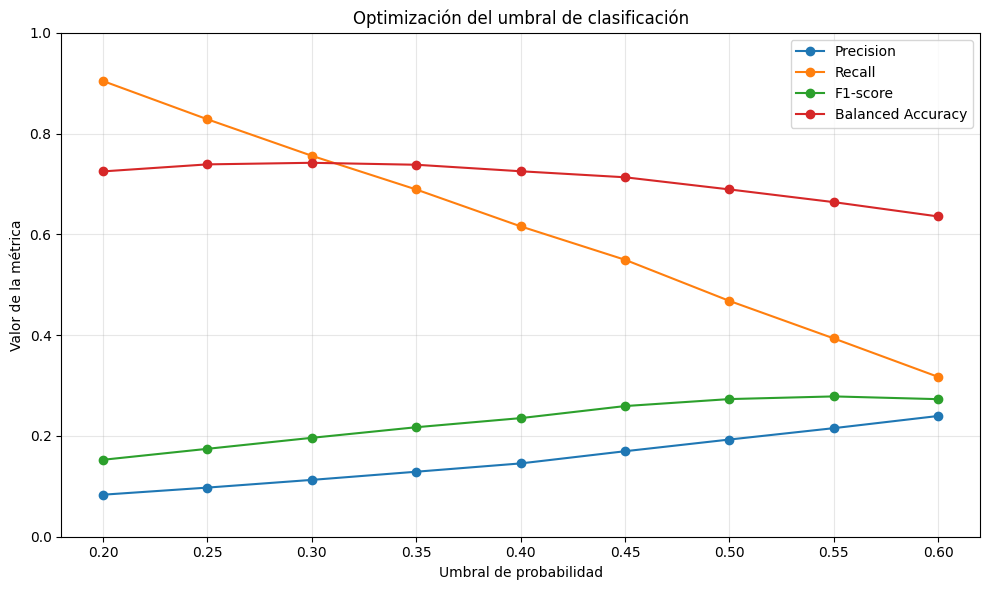

In [35]:

# ---------------------------------------------------------
# VISUALIZACIÓN DEL COMPORTAMIENTO DE LOS UMBRALES
# ---------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    tabla_umbrales["Umbral"],
    tabla_umbrales["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    tabla_umbrales["Umbral"],
    tabla_umbrales["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    tabla_umbrales["Umbral"],
    tabla_umbrales["F1_score"],
    marker="o",
    label="F1-score"
)

plt.plot(
    tabla_umbrales["Umbral"],
    tabla_umbrales["Balanced_Accuracy"],
    marker="o",
    label="Balanced Accuracy"
)

plt.title("Optimización del umbral de clasificación")
plt.xlabel("Umbral de probabilidad")
plt.ylabel("Valor de la métrica")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [36]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

print("Herramientas importadas correctamente")


Herramientas importadas correctamente


In [37]:

# ---------------------------------------------------------
# RECONSTRUIR EL MODELO PRINCIPAL
# ---------------------------------------------------------

# Crear una copia independiente del preprocesador
preprocesador_principal = clone(preprocesador)

# Construir nuevamente el pipeline principal
pipeline_rf = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador_principal
        ),
        (
            "clasificador",
            RandomForestClassifier(
                n_estimators=300,
                max_features="sqrt",
                min_samples_leaf=2,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Entrenando nuevamente el modelo principal...")

pipeline_rf.fit(X_train, y_train)

print("Modelo principal entrenado correctamente")


Entrenando nuevamente el modelo principal...
Modelo principal entrenado correctamente


In [38]:

# ---------------------------------------------------------
# VERIFICAR DIMENSIONES DEL PREPROCESAMIENTO
# ---------------------------------------------------------

X_train_transformado = (
    pipeline_rf
    .named_steps["preprocesamiento"]
    .transform(X_train)
)

X_test_transformado = (
    pipeline_rf
    .named_steps["preprocesamiento"]
    .transform(X_test)
)

print(
    "Características de entrenamiento:",
    X_train_transformado.shape[1]
)

print(
    "Características de prueba:",
    X_test_transformado.shape[1]
)

print(
    "Características esperadas por Random Forest:",
    pipeline_rf.named_steps["clasificador"].n_features_in_
)


Características de entrenamiento: 364
Características de prueba: 364
Características esperadas por Random Forest: 364


In [39]:

# ---------------------------------------------------------
# PREDICCIONES CON EL MODELO CORREGIDO
# ---------------------------------------------------------

probabilidades_test = pipeline_rf.predict_proba(X_test)

clases = list(
    pipeline_rf.named_steps["clasificador"].classes_
)

indice_muertos = clases.index("CON MUERTOS")

prob_muertos_test = probabilidades_test[:, indice_muertos]

# Aplicar el umbral seleccionado en validación
umbral_seleccionado = 0.55

y_pred_055 = np.where(
    prob_muertos_test >= umbral_seleccionado,
    "CON MUERTOS",
    "CON HERIDOS"
)

print("Predicciones generadas correctamente")
print("Total de predicciones:", len(y_pred_055))


Predicciones generadas correctamente
Total de predicciones: 102186


In [40]:

# ---------------------------------------------------------
# MÉTRICAS FINALES DEL MODELO CON UMBRAL 0.55
# ---------------------------------------------------------

accuracy_055 = accuracy_score(y_test, y_pred_055)

balanced_055 = balanced_accuracy_score(
    y_test, y_pred_055
)

precision_055 = precision_score(
    y_test, y_pred_055,
    pos_label="CON MUERTOS",
    zero_division=0
)

recall_055 = recall_score(
    y_test, y_pred_055,
    pos_label="CON MUERTOS",
    zero_division=0
)

f1_055 = f1_score(
    y_test, y_pred_055,
    pos_label="CON MUERTOS",
    zero_division=0
)

roc_auc_055 = roc_auc_score(
    (y_test == "CON MUERTOS").astype(int),
    prob_muertos_test
)

ap_055 = average_precision_score(
    (y_test == "CON MUERTOS").astype(int),
    prob_muertos_test
)

metricas_finales = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision - CON MUERTOS",
        "Recall - CON MUERTOS",
        "F1-score - CON MUERTOS",
        "ROC-AUC",
        "Average Precision"
    ],
    "Resultado": [
        accuracy_055,
        balanced_055,
        precision_055,
        recall_055,
        f1_055,
        roc_auc_055,
        ap_055
    ]
})

display(metricas_finales.round(4))


,Métrica,Resultado
0,Accuracy,0.8278
1,Balanced Accuracy,0.6693
2,Precision - CON MUERTOS,0.2235
3,Recall - CON MUERTOS,0.4813
4,F1-score - CON MUERTOS,0.3053
5,ROC-AUC,0.7693
6,Average Precision,0.2369


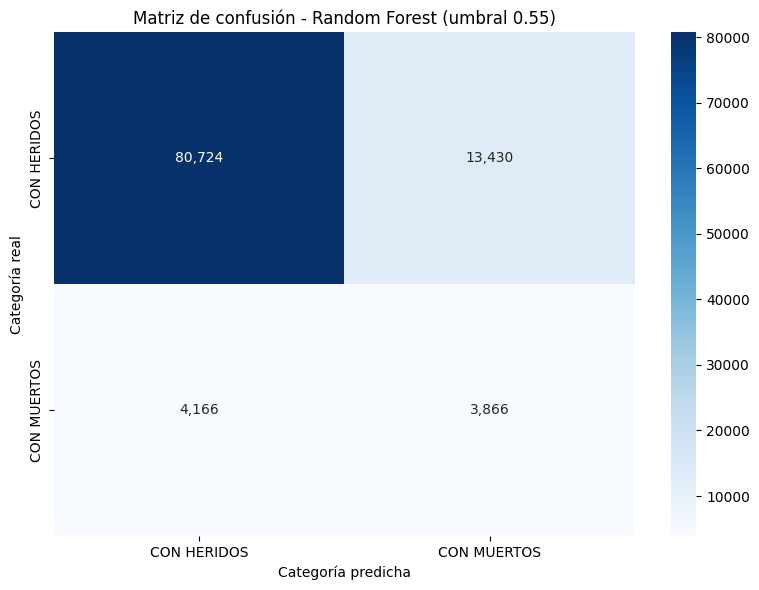


Informe de clasificación:
              precision    recall  f1-score   support

 CON HERIDOS     0.9509    0.8574    0.9017     94154
 CON MUERTOS     0.2235    0.4813    0.3053      8032

    accuracy                         0.8278    102186
   macro avg     0.5872    0.6693    0.6035    102186
weighted avg     0.8937    0.8278    0.8548    102186



In [41]:

# ---------------------------------------------------------
# MATRIZ DE CONFUSIÓN FINAL
# ---------------------------------------------------------

etiquetas = ["CON HERIDOS", "CON MUERTOS"]

matriz_055 = confusion_matrix(
    y_test,
    y_pred_055,
    labels=etiquetas
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_055,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=etiquetas,
    yticklabels=etiquetas
)

plt.title("Matriz de confusión - Random Forest (umbral 0.55)")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")

plt.tight_layout()
plt.show()

print("\nInforme de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_055,
        labels=etiquetas,
        digits=4,
        zero_division=0
    )
)


In [42]:

# ---------------------------------------------------------
# COMPARACIÓN DEL MODELO INICIAL Y OPTIMIZADO
# ---------------------------------------------------------

comparacion = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision - CON MUERTOS",
        "Recall - CON MUERTOS",
        "F1-score - CON MUERTOS"
    ],
    "Modelo inicial": [
        accuracy_score(y_test, y_pred),
        balanced_accuracy_score(y_test, y_pred),
        precision_score(
            y_test, y_pred,
            pos_label="CON MUERTOS",
            zero_division=0
        ),
        recall_score(
            y_test, y_pred,
            pos_label="CON MUERTOS",
            zero_division=0
        ),
        f1_score(
            y_test, y_pred,
            pos_label="CON MUERTOS",
            zero_division=0
        )
    ],
    "Modelo umbral 0.55": [
        accuracy_055,
        balanced_055,
        precision_055,
        recall_055,
        f1_055
    ]
})

display(comparacion.round(4))


,Métrica,Modelo inicial,Modelo umbral 0.55
0,Accuracy,0.7867,0.8278
1,Balanced Accuracy,0.6856,0.6693
2,Precision - CON MUERTOS,0.1988,0.2235
3,Recall - CON MUERTOS,0.5656,0.4813
4,F1-score - CON MUERTOS,0.2942,0.3053


,Caracteristica,Importancia
260,categoricas__MUNICIPIO_ACCIDENTE_MEDELLIN,0.12349
3,numericas__MES_ACCIDENTE,0.10768
111,categoricas__DEPARTAMENTO_ACCIDENTE_ANTIOQUIA,0.09071
0,numericas__MODELO_VEHICULO,0.08419
1,numericas__EDAD_VEHICULO,0.08407
2,numericas__ANIO_ACCIDENTE,0.03759
98,categoricas__TIPO_VEHICULO_AUTOMOVIL,0.02573
101,categoricas__TIPO_VEHICULO_CAMION,0.02151
108,categoricas__TIPO_VEHICULO_TRACTOCAMION,0.02006
363,categoricas__MUNICIPIO_ACCIDENTE_infrequent_sk...,0.01657


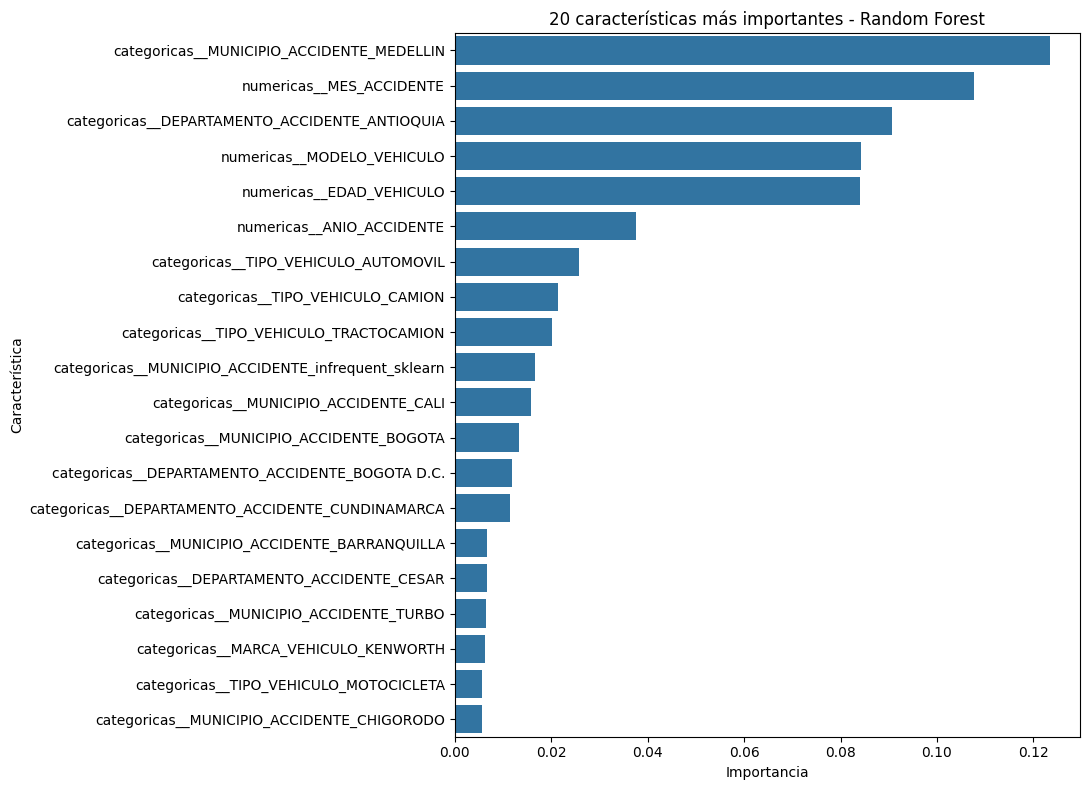

In [43]:

# ---------------------------------------------------------
# IMPORTANCIA DE LAS VARIABLES - RANDOM FOREST
# ---------------------------------------------------------

# Obtener el clasificador entrenado
clasificador = pipeline_rf.named_steps["clasificador"]

# Obtener los nombres de las características
nombres_caracteristicas = (
    pipeline_rf
    .named_steps["preprocesamiento"]
    .get_feature_names_out()
)

# Obtener la importancia de cada característica
importancias = clasificador.feature_importances_

# Construir DataFrame
importancia_variables = pd.DataFrame({
    "Caracteristica": nombres_caracteristicas,
    "Importancia": importancias
})

# Ordenar de mayor a menor
importancia_variables = importancia_variables.sort_values(
    by="Importancia",
    ascending=False
)

# Mostrar las 20 características más importantes
display(importancia_variables.head(20).round(5))

# Gráfico
plt.figure(figsize=(11, 8))

sns.barplot(
    data=importancia_variables.head(20),
    x="Importancia",
    y="Caracteristica"
)

plt.title("20 características más importantes - Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()


Calculando importancia por permutación...


,Variable,Importancia_media,Desviacion_estandar
7,MUNICIPIO_ACCIDENTE,0.08090,0.00189
6,DEPARTAMENTO_ACCIDENTE,0.06264,0.00513
2,TIPO_VEHICULO,0.03331,0.00360
0,MARCA_VEHICULO,0.00754,0.00201
5,MES_ACCIDENTE,0.00051,0.00222
4,ANIO_ACCIDENTE,0.00000,0.00000
3,EDAD_VEHICULO,-0.00178,0.00190
1,MODELO_VEHICULO,-0.00188,0.00116


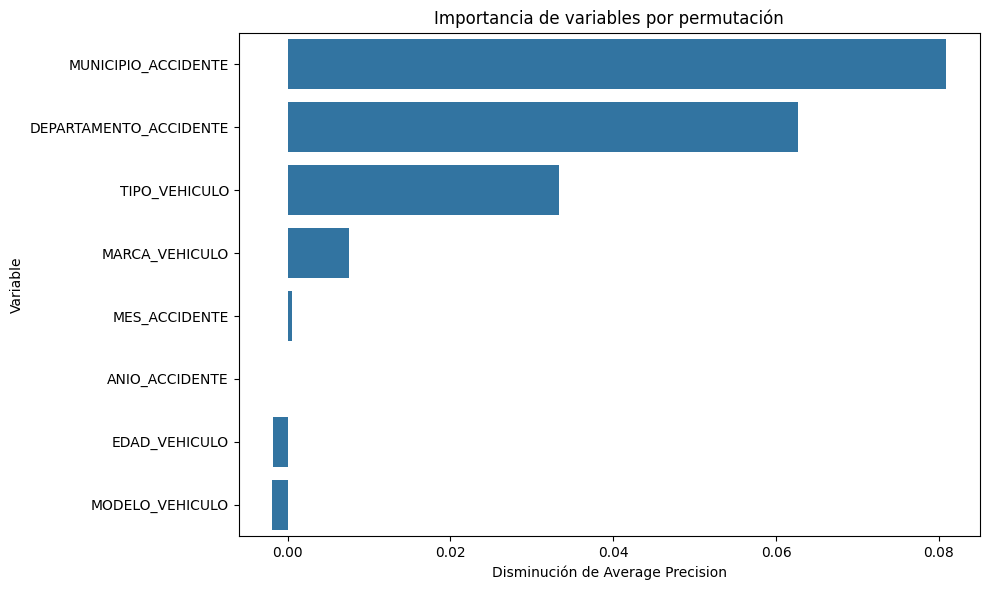

In [44]:

# ---------------------------------------------------------
# IMPORTANCIA DE VARIABLES POR PERMUTACIÓN
# CORRECCIÓN PARA ETIQUETAS DE TEXTO
# ---------------------------------------------------------

from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

# ---------------------------------------------------------
# 1. Crear una función personalizada de evaluación
# ---------------------------------------------------------

def average_precision_muertos(estimator, X, y):

    # Obtener las clases reconocidas por el clasificador
    clases = list(
        estimator.named_steps["clasificador"].classes_
    )

    # Identificar la posición de CON MUERTOS
    indice_muertos = clases.index("CON MUERTOS")

    # Obtener las probabilidades de predicción
    probabilidades = estimator.predict_proba(X)

    # Extraer la probabilidad de la clase CON MUERTOS
    prob_muertos = probabilidades[:, indice_muertos]

    # Convertir temporalmente la variable objetivo:
    # CON MUERTOS = 1
    # CON HERIDOS = 0
    y_binario = (
        pd.Series(y).to_numpy() == "CON MUERTOS"
    ).astype(int)

    # Calcular Average Precision
    return average_precision_score(
        y_binario,
        prob_muertos
    )


# ---------------------------------------------------------
# 2. Seleccionar una muestra del conjunto de prueba
# ---------------------------------------------------------

X_muestra = X_test.sample(
    n=min(20000, len(X_test)),
    random_state=42
)

y_muestra = y_test.loc[X_muestra.index]


# ---------------------------------------------------------
# 3. Calcular importancia por permutación
# ---------------------------------------------------------

print("Calculando importancia por permutación...")

resultado_permutacion = permutation_importance(
    estimator=pipeline_rf,
    X=X_muestra,
    y=y_muestra,
    scoring=average_precision_muertos,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)


# ---------------------------------------------------------
# 4. Construir tabla de importancia
# ---------------------------------------------------------

importancia_permutacion = pd.DataFrame({
    "Variable": X_muestra.columns,
    "Importancia_media": resultado_permutacion.importances_mean,
    "Desviacion_estandar": resultado_permutacion.importances_std
})

importancia_permutacion = importancia_permutacion.sort_values(
    by="Importancia_media",
    ascending=False
)

display(importancia_permutacion.round(5))


# ---------------------------------------------------------
# 5. Visualizar resultados
# ---------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importancia_permutacion,
    x="Importancia_media",
    y="Variable"
)

plt.title(
    "Importancia de variables por permutación"
)

plt.xlabel(
    "Disminución de Average Precision"
)

plt.ylabel("Variable")

plt.tight_layout()
plt.show()


In [45]:

# ---------------------------------------------------------
# GENERALIZACIÓN GEOGRÁFICA
# SEPARACIÓN POR MUNICIPIO
# ---------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# X e y corresponden a las variables predictoras
# y la variable objetivo definidas anteriormente.

# Identificar los municipios como grupos
grupos_municipio = X["MUNICIPIO_ACCIDENTE"]

# Crear una división que mantenga cada municipio
# exclusivamente en entrenamiento o en prueba.
separador_geo = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

indices_train_geo, indices_test_geo = next(
    separador_geo.split(
        X,
        y,
        groups=grupos_municipio
    )
)

# Construir los conjuntos
X_train_geo = X.iloc[indices_train_geo].copy()
X_test_geo = X.iloc[indices_test_geo].copy()

y_train_geo = y.iloc[indices_train_geo].copy()
y_test_geo = y.iloc[indices_test_geo].copy()

# Verificar municipios
municipios_train = set(
    X_train_geo["MUNICIPIO_ACCIDENTE"]
)

municipios_test = set(
    X_test_geo["MUNICIPIO_ACCIDENTE"]
)

municipios_compartidos = (
    municipios_train.intersection(municipios_test)
)

print("REGISTROS DE ENTRENAMIENTO:", X_train_geo.shape)
print("REGISTROS DE PRUEBA:", X_test_geo.shape)

print("Municipios en entrenamiento:", len(municipios_train))
print("Municipios en prueba:", len(municipios_test))

print("Municipios compartidos:", len(municipios_compartidos))

print("\nDistribución de clases en entrenamiento:")
display(y_train_geo.value_counts(normalize=True).mul(100).round(2))

print("\nDistribución de clases en prueba:")
display(y_test_geo.value_counts(normalize=True).mul(100).round(2))


REGISTROS DE ENTRENAMIENTO: (411330, 8)
REGISTROS DE PRUEBA: (39005, 8)
Municipios en entrenamiento: 530
Municipios en prueba: 133
Municipios compartidos: 0

Distribución de clases en entrenamiento:


GRAVEDAD_ACCIDENTE
CON HERIDOS    95.08
CON MUERTOS     4.92
Name: proportion, dtype: Float64


Distribución de clases en prueba:


GRAVEDAD_ACCIDENTE
CON HERIDOS    90.67
CON MUERTOS     9.33
Name: proportion, dtype: Float64

In [46]:

# ---------------------------------------------------------
# ENTRENAMIENTO DEL MODELO CON SEPARACIÓN GEOGRÁFICA
# ---------------------------------------------------------

# Crear una copia independiente del pipeline
pipeline_geo = clone(pipeline_rf)

print("Iniciando entrenamiento geográfico...")

pipeline_geo.fit(
    X_train_geo,
    y_train_geo
)

print("Entrenamiento geográfico finalizado.")


Iniciando entrenamiento geográfico...
Entrenamiento geográfico finalizado.


In [47]:

# ---------------------------------------------------------
# CREAR Y ENTRENAR EL MODELO DE GENERALIZACIÓN GEOGRÁFICA
# ---------------------------------------------------------

from sklearn.base import clone

# Verificar que existan los conjuntos geográficos
assert "X_train_geo" in globals(), "Ejecuta primero la celda de separación geográfica."
assert "y_train_geo" in globals(), "No se encuentra y_train_geo."
assert "pipeline_rf" in globals(), "No se encuentra el pipeline original."

# Crear una copia independiente del pipeline
pipeline_geo = clone(pipeline_rf)

# Entrenar el modelo
print("Iniciando entrenamiento geográfico...")

pipeline_geo.fit(
    X_train_geo,
    y_train_geo
)

print("Entrenamiento finalizado correctamente.")

# Confirmar que el modelo existe
print("Modelo:", type(pipeline_geo).__name__)
print("Características de entrenamiento:", X_train_geo.shape[1])


Iniciando entrenamiento geográfico...
Entrenamiento finalizado correctamente.
Modelo: Pipeline
Características de entrenamiento: 8


In [49]:

# ---------------------------------------------------------
# GENERAR PREDICCIONES DEL MODELO GEOGRÁFICO
# ---------------------------------------------------------

# Verificar que el modelo y los datos existan
assert "pipeline_geo" in globals(), "Primero debes entrenar pipeline_geo."
assert "X_test_geo" in globals(), "No existe X_test_geo."
assert "y_test_geo" in globals(), "No existe y_test_geo."

# Generar predicciones
y_pred_geo = pipeline_geo.predict(X_test_geo)

print("Predicciones generadas correctamente.")
print("Total de predicciones:", len(y_pred_geo))

# Verificar resultados
print("\nPrimeras 10 predicciones:")
print(y_pred_geo[:10])


Predicciones generadas correctamente.
Total de predicciones: 39005

Primeras 10 predicciones:
['CON MUERTOS' 'CON MUERTOS' 'CON MUERTOS' 'CON HERIDOS' 'CON MUERTOS'
 'CON MUERTOS' 'CON MUERTOS' 'CON MUERTOS' 'CON HERIDOS' 'CON MUERTOS']


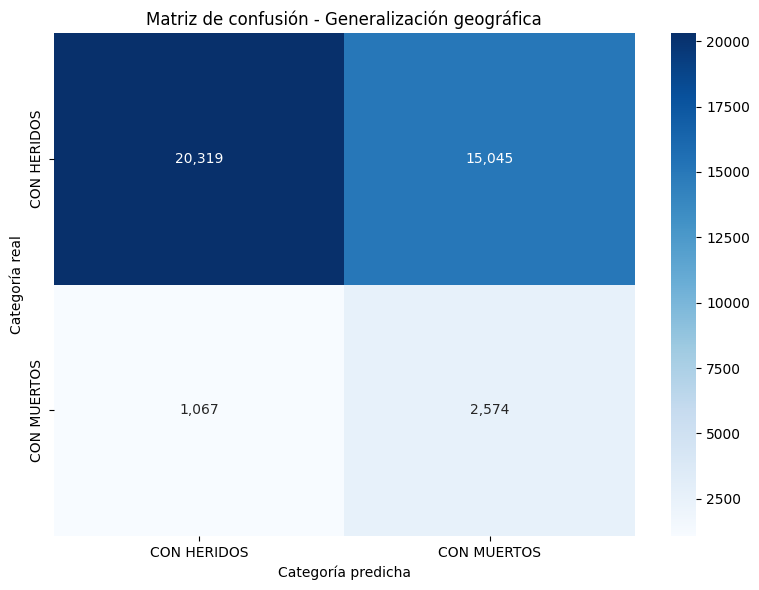

In [50]:

# ---------------------------------------------------------
# MATRIZ DE CONFUSIÓN - GENERALIZACIÓN GEOGRÁFICA
# ---------------------------------------------------------

etiquetas_geo = ["CON HERIDOS", "CON MUERTOS"]

matriz_geo = confusion_matrix(
    y_test_geo,
    y_pred_geo,
    labels=etiquetas_geo
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_geo,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=etiquetas_geo,
    yticklabels=etiquetas_geo
)

plt.title("Matriz de confusión - Generalización geográfica")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")

plt.tight_layout()
plt.show()


In [51]:

# =========================================================
# GENERALIZACIÓN TEMPORAL - RANDOM FOREST
# SEPARACIÓN CRONOLÓGICA DE LOS REGISTROS
# =========================================================

import pandas as pd
import numpy as np

# Verificar que existan las variables
assert "X" in globals(), "No existe la variable X."
assert "y" in globals(), "No existe la variable y."

assert "ANIO_ACCIDENTE" in X.columns, (
    "No se encuentra ANIO_ACCIDENTE en X."
)

# Identificar los años de cada registro
anios = X["ANIO_ACCIDENTE"]

# Crear máscaras temporales
mascara_train = anios.between(2022, 2024)
mascara_test_2025 = anios == 2025
mascara_test_2026 = anios == 2026

# Construir conjuntos de entrenamiento
X_train_temp = X.loc[mascara_train].copy()
y_train_temp = y.loc[mascara_train].copy()

# Construir conjunto de prueba 2025
X_test_2025 = X.loc[mascara_test_2025].copy()
y_test_2025 = y.loc[mascara_test_2025].copy()

# Construir conjunto de evaluación 2026
X_test_2026 = X.loc[mascara_test_2026].copy()
y_test_2026 = y.loc[mascara_test_2026].copy()

# Mostrar dimensiones
print("=" * 60)
print("DISTRIBUCIÓN DE LOS CONJUNTOS TEMPORALES")
print("=" * 60)

print("Entrenamiento 2022-2024:", X_train_temp.shape)
print("Prueba 2025:", X_test_2025.shape)
print("Evaluación 2026:", X_test_2026.shape)

# Verificar que los periodos estén correctamente separados
print("\nAños de entrenamiento:")
print(sorted(X_train_temp["ANIO_ACCIDENTE"].unique()))

print("\nAños de prueba:")
print(sorted(X_test_2025["ANIO_ACCIDENTE"].unique()))

print("\nAños de evaluación adicional:")
print(sorted(X_test_2026["ANIO_ACCIDENTE"].unique()))

# Distribución de las clases
print("\nDistribución de clases - Entrenamiento:")
display(
    y_train_temp.value_counts(normalize=True)
    .mul(100).round(2)
)

print("\nDistribución de clases - Prueba 2025:")
display(
    y_test_2025.value_counts(normalize=True)
    .mul(100).round(2)
)

print("\nDistribución de clases - Evaluación 2026:")
display(
    y_test_2026.value_counts(normalize=True)
    .mul(100).round(2)
)

# Validaciones
assert len(X_train_temp) > 0
assert len(X_test_2025) > 0
assert len(X_test_2026) > 0

assert X_train_temp["ANIO_ACCIDENTE"].max() < 2025
assert X_test_2025["ANIO_ACCIDENTE"].min() == 2025
assert X_test_2026["ANIO_ACCIDENTE"].min() == 2026

print("\nSeparación temporal realizada correctamente.")


DISTRIBUCIÓN DE LOS CONJUNTOS TEMPORALES
Entrenamiento 2022-2024: (348149, 8)
Prueba 2025: (66891, 8)
Evaluación 2026: (35295, 8)

Años de entrenamiento:
[np.int32(2022), np.int32(2023), np.int32(2024)]

Años de prueba:
[np.int32(2025)]

Años de evaluación adicional:
[np.int32(2026)]

Distribución de clases - Entrenamiento:


GRAVEDAD_ACCIDENTE
CON HERIDOS    95.44
CON MUERTOS     4.56
Name: proportion, dtype: Float64


Distribución de clases - Prueba 2025:


GRAVEDAD_ACCIDENTE
CON HERIDOS    92.54
CON MUERTOS     7.46
Name: proportion, dtype: Float64


Distribución de clases - Evaluación 2026:


GRAVEDAD_ACCIDENTE
CON HERIDOS    91.38
CON MUERTOS     8.62
Name: proportion, dtype: Float64


Separación temporal realizada correctamente.


In [52]:

# =========================================================
# ENTRENAMIENTO DEL MODELO TEMPORAL
# =========================================================

from sklearn.base import clone

# Crear una copia independiente del pipeline
pipeline_temp = clone(pipeline_rf)

print("Iniciando entrenamiento temporal...")

# Entrenar exclusivamente con información 2022-2024
pipeline_temp.fit(
    X_train_temp,
    y_train_temp
)

print("\nEntrenamiento temporal finalizado.")

print("Registros utilizados:", len(X_train_temp))
print("Variables predictoras:", X_train_temp.shape[1])


Iniciando entrenamiento temporal...

Entrenamiento temporal finalizado.
Registros utilizados: 348149
Variables predictoras: 8


In [53]:

# =========================================================
# FUNCIÓN DE EVALUACIÓN DEL MODELO
# =========================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

def evaluar_modelo_temporal(modelo, X_test, y_test, nombre_periodo):

    # Generar predicciones
    predicciones = modelo.predict(X_test)

    # Obtener probabilidades
    probabilidades = modelo.predict_proba(X_test)

    # Identificar la posición de CON MUERTOS
    clases = list(
        modelo.named_steps["clasificador"].classes_
    )

    indice_muertos = clases.index("CON MUERTOS")

    prob_muertos = probabilidades[:, indice_muertos]

    # Convertir la clase objetivo a formato binario
    y_test_binario = (
        y_test == "CON MUERTOS"
    ).astype(int)

    # Calcular métricas
    resultados = {
        "Periodo": nombre_periodo,

        "Accuracy": accuracy_score(
            y_test, predicciones
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predicciones
        ),

        "Precision - CON MUERTOS": precision_score(
            y_test,
            predicciones,
            pos_label="CON MUERTOS",
            zero_division=0
        ),

        "Recall - CON MUERTOS": recall_score(
            y_test,
            predicciones,
            pos_label="CON MUERTOS",
            zero_division=0
        ),

        "F1-score - CON MUERTOS": f1_score(
            y_test,
            predicciones,
            pos_label="CON MUERTOS",
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_test_binario,
            prob_muertos
        ),

        "Average Precision": average_precision_score(
            y_test_binario,
            prob_muertos
        )
    }

    print("\n" + "=" * 60)
    print("EVALUACIÓN:", nombre_periodo)
    print("=" * 60)

    print("\nInforme de clasificación:")

    print(
        classification_report(
            y_test,
            predicciones,
            labels=["CON HERIDOS", "CON MUERTOS"],
            digits=4,
            zero_division=0
        )
    )

    return resultados, predicciones, prob_muertos


In [54]:

# =========================================================
# EVALUACIÓN TEMPORAL - AÑO 2026
# =========================================================

resultados_2026, y_pred_2026, prob_muertos_2026 = (
    evaluar_modelo_temporal(
        pipeline_temp,
        X_test_2026,
        y_test_2026,
        "2026"
    )
)

print("\nMétricas de evaluación 2026:")

display(
    pd.DataFrame([resultados_2026]).round(4)
)



EVALUACIÓN: 2026

Informe de clasificación:
              precision    recall  f1-score   support

 CON HERIDOS     0.9514    0.7924    0.8646     32251
 CON MUERTOS     0.2062    0.5713    0.3030      3044

    accuracy                         0.7733     35295
   macro avg     0.5788    0.6818    0.5838     35295
weighted avg     0.8871    0.7733    0.8162     35295


Métricas de evaluación 2026:


,Periodo,Accuracy,Balanced Accuracy,Precision - CON MUERTOS,Recall - CON MUERTOS,F1-score - CON MUERTOS,ROC-AUC,Average Precision
0,2026,0.7733,0.6818,0.2062,0.5713,0.303,0.7653,0.2453


In [57]:

# Verificar las variables necesarias

print("resultados_2025:", "resultados_2025" in globals())
print("resultados_2026:", "resultados_2026" in globals())
print("pandas (pd):", "pd" in globals())
print("matplotlib (plt):", "plt" in globals())

if "resultados_2025" in globals():
    print("\nResultados 2025:")
    print(resultados_2025)

if "resultados_2026" in globals():
    print("\nResultados 2026:")
    print(resultados_2026)


resultados_2025: False
resultados_2026: True
pandas (pd): True
matplotlib (plt): True

Resultados 2026:
{'Periodo': '2026', 'Accuracy': 0.7733106672333192, 'Balanced Accuracy': 0.6818331550680559, 'Precision - CON MUERTOS': 0.20616478956727918, 'Recall - CON MUERTOS': 0.5712877792378449, 'F1-score - CON MUERTOS': 0.3029880651624706, 'ROC-AUC': 0.7653368814445791, 'Average Precision': 0.24533673990101143}


In [59]:

# =========================================================
# GENERAR RESULTADOS DE EVALUACIÓN TEMPORAL
# 2025 Y 2026
# =========================================================

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

# ---------------------------------------------------------
# 1. Verificar que el modelo esté entrenado
# ---------------------------------------------------------

assert "pipeline_temp" in globals(), (
    "No existe pipeline_temp. Debes ejecutar primero "
    "la celda de entrenamiento temporal."
)

assert "X_test_2025" in globals(), "Falta X_test_2025."
assert "y_test_2025" in globals(), "Falta y_test_2025."
assert "X_test_2026" in globals(), "Falta X_test_2026."
assert "y_test_2026" in globals(), "Falta y_test_2026."

# ---------------------------------------------------------
# 2. Función para calcular las métricas
# ---------------------------------------------------------

def calcular_metricas_temporales(modelo, X_test, y_test, periodo):

    # Predicciones
    predicciones = modelo.predict(X_test)

    # Probabilidades
    probabilidades = modelo.predict_proba(X_test)

    # Identificar la clase CON MUERTOS
    clases = list(
        modelo.named_steps["clasificador"].classes_
    )

    indice_muertos = clases.index("CON MUERTOS")

    prob_muertos = probabilidades[:, indice_muertos]

    # Variable objetivo binaria
    y_binario = (y_test == "CON MUERTOS").astype(int)

    # Calcular métricas
    resultados = {
        "Periodo": periodo,

        "Accuracy": accuracy_score(
            y_test, predicciones
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predicciones
        ),

        "Precision - CON MUERTOS": precision_score(
            y_test,
            predicciones,
            pos_label="CON MUERTOS",
            zero_division=0
        ),

        "Recall - CON MUERTOS": recall_score(
            y_test,
            predicciones,
            pos_label="CON MUERTOS",
            zero_division=0
        ),

        "F1-score - CON MUERTOS": f1_score(
            y_test,
            predicciones,
            pos_label="CON MUERTOS",
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_binario, prob_muertos
        ),

        "Average Precision": average_precision_score(
            y_binario, prob_muertos
        )
    }

    print("\nEvaluación:", periodo)

    print(
        classification_report(
            y_test,
            predicciones,
            labels=["CON HERIDOS", "CON MUERTOS"],
            digits=4,
            zero_division=0
        )
    )

    return resultados, predicciones, prob_muertos


# ---------------------------------------------------------
# 3. Evaluar el año 2025
# ---------------------------------------------------------

print("Evaluando registros de 2025...")

resultados_2025, y_pred_2025, prob_muertos_2025 = (
    calcular_metricas_temporales(
        pipeline_temp,
        X_test_2025,
        y_test_2025,
        "2025"
    )
)

# ---------------------------------------------------------
# 4. Evaluar el año 2026
# ---------------------------------------------------------

print("\nEvaluando registros de 2026...")

resultados_2026, y_pred_2026, prob_muertos_2026 = (
    calcular_metricas_temporales(
        pipeline_temp,
        X_test_2026,
        y_test_2026,
        "2026"
    )
)

print("\nLas dos evaluaciones finalizaron correctamente.")


Evaluando registros de 2025...

Evaluación: 2025
              precision    recall  f1-score   support

 CON HERIDOS     0.9584    0.8124    0.8794     61903
 CON MUERTOS     0.1945    0.5621    0.2890      4988

    accuracy                         0.7937     66891
   macro avg     0.5764    0.6873    0.5842     66891
weighted avg     0.9014    0.7937    0.8353     66891


Evaluando registros de 2026...

Evaluación: 2026
              precision    recall  f1-score   support

 CON HERIDOS     0.9514    0.7924    0.8646     32251
 CON MUERTOS     0.2062    0.5713    0.3030      3044

    accuracy                         0.7733     35295
   macro avg     0.5788    0.6818    0.5838     35295
weighted avg     0.8871    0.7733    0.8162     35295


Las dos evaluaciones finalizaron correctamente.


COMPARACIÓN DEL DESEMPEÑO TEMPORAL


,Accuracy,Balanced Accuracy,Precision - CON MUERTOS,Recall - CON MUERTOS,F1-score - CON MUERTOS,ROC-AUC,Average Precision
Periodo,,,,,,,
2025,0.7937,0.6873,0.1945,0.5621,0.289,0.7710,0.2323
2026,0.7733,0.6818,0.2062,0.5713,0.303,0.7653,0.2453


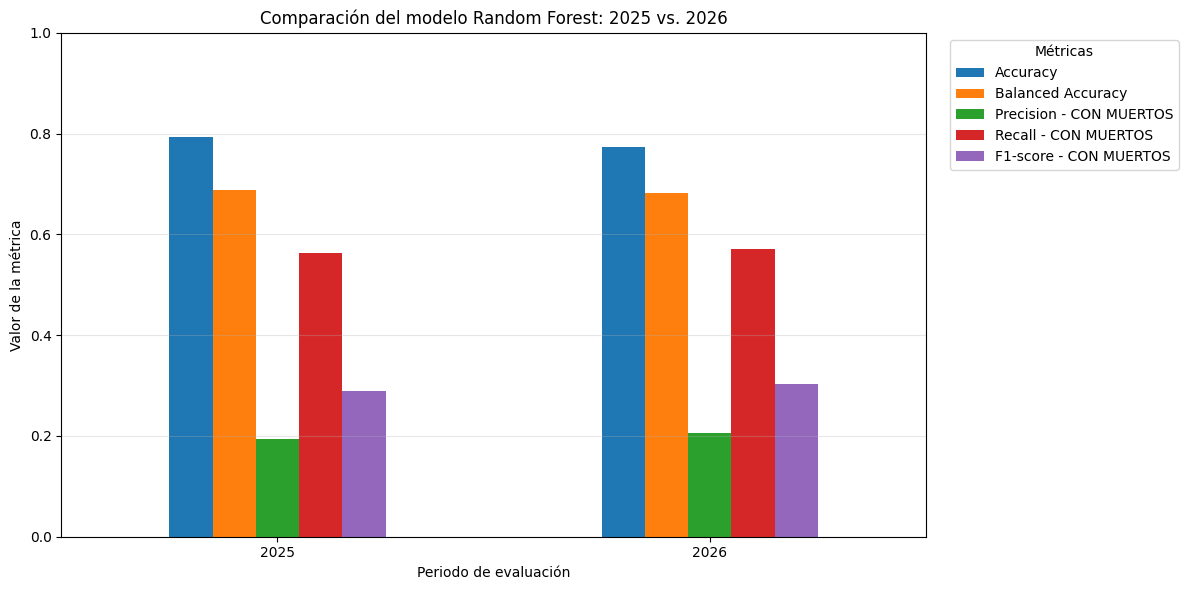

In [60]:

# =========================================================
# COMPARACIÓN DE RESULTADOS TEMPORALES
# =========================================================

import matplotlib.pyplot as plt

comparacion_temporal = pd.DataFrame([
    resultados_2025,
    resultados_2026
])

comparacion_temporal.set_index(
    "Periodo",
    inplace=True
)

print("COMPARACIÓN DEL DESEMPEÑO TEMPORAL")

display(comparacion_temporal.round(4))

# Gráfica de métricas principales
metricas_grafico = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision - CON MUERTOS",
    "Recall - CON MUERTOS",
    "F1-score - CON MUERTOS"
]

ax = comparacion_temporal[
    metricas_grafico
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

ax.set_title(
    "Comparación del modelo Random Forest: 2025 vs. 2026"
)

ax.set_ylabel("Valor de la métrica")
ax.set_xlabel("Periodo de evaluación")

ax.legend(
    title="Métricas",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
